# Card & Krueger (1994) 复现 · 独立扩展：用 QCEW 官方数据做县层面 DiD

主要思路：

> **把数据来源从"电话调查的门店级样本"换成"BLS 官方行政工资记录（QCEW / ES-202）的县级汇总"，检验最低工资上调对 NJ 县相对 PA 县"餐饮业"总就业的影响。**

---

## 0. 这个扩展是如何"延伸"原论文的

先回顾原论文（Card & Krueger 1994, AER）做了什么：

| 维度 | 原论文 | 本扩展 |
|---|---|---|
| **数据来源** | 作者自己做的**电话调查**（410 家快餐店） | **BLS QCEW**（季度就业与工资普查，即 ES-202 的公开版）——来自失业保险缴款的**行政记录** |
| **分析单位** | **门店（餐厅）** | **县（county）** |
| **结果变量** | 全职当量就业 FTE（全职 + 经理 + 0.5×兼职） | 县内"餐饮场所"（SIC 58 Eating and Drinking Places）的**总就业人数** |
| **处理/对照** | NJ 门店 vs PA 门店 | NJ 的 21 个县 vs PA 的 67 个县 |
| **时间** | 1992 年 2–3 月（前）vs 11–12 月（后） | 1992 年 Q1 的 2–3 月 vs Q4 的 11–12 月（完全对齐） |
| **方法** | 门店级 DiD | 县层面 DiD（对数就业变化对 NJ 虚拟变量回归） |

**创新之处：**

1. **更换数据样本**：原文靠电话调查，存在测量误差争议（这也是 Neumark-Wascher 2000 攻击的点）。QCEW 是**行政工资记录**，几乎覆盖全部雇主，不依赖受访者回忆。
2. **更换分析维度**：从微观门店升到宏观县级，检验"加总层面"是否也看不出就业损失。
3. **更换被解释变量**：从"几家快餐连锁"扩大到"全县所有餐饮场所（含正餐、酒吧）"。

**预期**：若最低工资真的大幅减少就业，我们应该看到 NJ 县餐饮业就业相对 PA 县**下降**；反之（下降很少、甚至相对上升）则支持原文结论。

> 数据来源：BLS QCEW，`sic_1992_qtrly_by_area.zip`（SIC 分类，1975–2000）。下载页 https://www.bls.gov/cew/downloadable-data-files.htm


## 1. 数据说明与字段字典

### 1.1 文件结构
这个 zip 里是 **3600 多个 CSV**，每个 CSV 对应一个地理区域（县 / 大都市区 MSA / 州）。文件名形如：

- `34001` 是 5 位 **FIPS 地理码**（前 2 位州 + 后 3 位县）：`34` = 新泽西 NJ，`42` = 宾夕法尼亚 PA。
- 文件内部是"该县 × 各行业 × 各所有权 × 4 个季度"的**长表**。

### 1.2 每个字段的含义（数据字典）

| 字段 | 含义 | 处理方式 |
|---|---|---|
| `area_fips` | 5 位 FIPS 地理码（州+县） | 用它识别 NJ/PA 县，构造 `state`、`nj` |
| `own_code` | 所有权代码：0=全部、1=联邦政府、2=州政府、3=地方政府、**5=私营** | 只保留 **5（私营）**，排除政府 |
| `industry_code` | SIC 行业码（带前缀），如 `SIC_0G581` | 只保留 **餐饮业 SIC 58/581/5810** |
| `agglvl_code` | 汇总层级：26=全县合计、27=县×所有权、28=行业大类…**30=县×3位SIC×所有权** | 用 **30** 取"县 × 3位SIC"的餐饮行 |
| `size_code` | 企业规模档（0=全部规模） | 用 0（全部规模） |
| `year` / `qtr` | 年份 / 季度（1–4） | `qtr==1` 为"前"、`qtr==4` 为"后" |
| `disclosure_code` | 披露/保密标记（空=正常；非空=因保密被隐藏） | 检查是否有被隐藏的数据 |
| `*_title` | 各代码的人类可读名称（如 "Atlantic County, New Jersey"） | 用于核对，不参与计算 |
| `qtrly_estabs_count` | 该季度**机构（门店）数** | 可作辅助变量 |
| `month1/2/3_emplvl` | 该季度**第 1/2/3 个月的就业人数** | **核心变量**，用来算"前/后"就业 |
| `total_qtrly_wages` | 季度总工资（美元） | 可算平均周薪 |
| `taxable_qtrly_wages` | 应税工资部分 | 本次不用 |
| `qtrly_contributions` | 雇主失业保险缴款 | 本次不用 |
| `avg_wkly_wage` | 平均周薪 | 可作辅助变量 |

**关键点**：`month1/2/3_emplvl` 三个字段是 QCEW 独有的——它给了每个季度内部三个月的就业。这正是我们能精确对齐 CK 调查时间（2–3 月 vs 11–12 月）的原因。


## 2. 读入数据

**输入**：`sic_1992_qtrly_by_area.zip`。**操作**：用 `zipfile` 直接在压缩包内定位 NJ（`34xxx`）和 PA（`42xxx`）的县文件，逐个读入。**输出**：`county_files` 列表（FIPS 码 + 文件名）。


In [1]:
# ===== 2. 读入 NJ/PA 县文件 =====
import zipfile, io, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display

ZIP = "../data/raw/sic_1992_qtrly_by_area.zip"   # 数据已移到 data/raw/（相对本 notebook 的路径）

with zipfile.ZipFile(ZIP) as z:
    all_names = [n for n in z.namelist() if n.endswith(".csv")]

# 用正则从文件名里提取 5 位 FIPS 码，例如 "34001 (Atlantic County, New Jersey).csv"
county_files = []
for n in all_names:
    m = re.search(r"\s(\d{5}) \(", n)
    if not m:
        continue
    fips = m.group(1)
    # 只保留 NJ(34) 和 PA(42) 的"县"：排除州合计(000)、州外(998)、未知(999)
    if fips[:2] in ("34", "42") and fips[2:] not in ("000", "998", "999"):
        county_files.append((fips, n))

print("找到县文件数:", len(county_files))
print("  NJ 县:", sum(1 for f, _ in county_files if f.startswith("34")))
print("  PA 县:", sum(1 for f, _ in county_files if f.startswith("42")))
print("示例:", county_files[:2])


找到县文件数: 88
  NJ 县: 21
  PA 县: 67
示例: [('34001', 'sic.1992.q1-q4.by_area/sic.1992.q1-q4 34001 (Atlantic County, New Jersey).csv'), ('34003', 'sic.1992.q1-q4.by_area/sic.1992.q1-q4 34003 (Bergen County, New Jersey).csv')]


## 3. 筛选与处理变量

**输入**：`county_files`。**操作**：对每个县文件——(1) 只保留餐饮业 + 私营的行；(2) 提取所需列；(3) 加 FIPS/州标识。**输出**：长表 `df`（县 × 季度）。

### 为什么这样筛选
- **行业** `industry_code`：QCEW 公开数据里最细的"餐厅"口径是 **SIC 58 "Eating and Drinking Places"**（含正餐 + 快餐 + 酒吧），代码有 `SIC_0G58`（2位）、`SIC_0G581`（3位）、`SIC_0G5810`（4位）三种，**数字完全相同**，只是汇总层级不同。我们取 `SIC_0G581`（`agglvl_code==30`，即"县 × 3位SIC × 所有权"），保证每县每季度只有一行、不重复。
- **所有权** `own_code==5`：只留**私营**，因为快餐店都是私营。
- 注意：这是"所有餐饮场所"，**不是**只挑快餐连锁——这是本扩展与原论文的关键差异。


In [7]:
# ===== 3. 逐个县读入并筛选 =====
KEEP_COLS = ["area_fips", "own_code", "industry_code", "agglvl_code",
             "year", "qtr", "disclosure_code",
             "qtrly_estabs_count", "month1_emplvl", "month2_emplvl", "month3_emplvl",
             "total_qtrly_wages", "avg_wkly_wage"]

frames = []
with zipfile.ZipFile(ZIP) as z:
    for fips, name in county_files:
        raw = pd.read_csv(io.BytesIO(z.read(name)))          # 读单个县 CSV
        eat = raw[(raw["industry_code"] == "SIC_0G581") &    # 餐饮业（3位SIC）
                  (raw["own_code"] == 5)].copy()             # 私营
        if eat.empty:                                        # 个别县可能没有该行业数据
            continue
        eat["fips"] = fips
        eat["state"] = fips[:2]                              # 前2位 = 州码
        frames.append(eat[KEEP_COLS + ["fips", "state"]])

df = pd.concat(frames, ignore_index=True)
print("餐饮业长表：", df.shape, "（行 = 县×季度）")
print("覆盖县数:", df["fips"].nunique())

# 把数值列从字符串转成真正的数值（QCEW CSV 里是文本，含逗号/引号）
num_cols = ["qtrly_estabs_count", "month1_emplvl", "month2_emplvl", "month3_emplvl",
            "total_qtrly_wages", "avg_wkly_wage"]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# 检查是否有因保密(disclosure)而被隐藏的缺失就业
# 说明：CSV 里 disclosure_code 为空时，pandas 读作 NaN；非空才表示"被保密隐藏"
hidden = df[df["disclosure_code"].notna()]
print("被保密隐藏的行数:", len(hidden))
display(df.head(4))


餐饮业长表： (352, 15) （行 = 县×季度）
覆盖县数: 88
被保密隐藏的行数: 0


,area_fips,own_code,industry_code,agglvl_code,year,qtr,disclosure_code,qtrly_estabs_count,month1_emplvl,month2_emplvl,month3_emplvl,total_qtrly_wages,avg_wkly_wage,fips,state
0,34001,5,SIC_0G581,30,1992,1,NaN,566,6377,6343,6442,15725999,189,34001,34
1,34001,5,SIC_0G581,30,1992,2,NaN,561,6660,7288,7906,18890479,199,34001,34
2,34001,5,SIC_0G581,30,1992,3,NaN,565,8097,8031,7503,22241168,217,34001,34
3,34001,5,SIC_0G581,30,1992,4,NaN,565,6979,6650,6349,18188479,210,34001,34


## 4. 构造 DiD 变量

**输入**：长表 `df`。**操作**：把"县 × 季度"压缩成"县 × 前/后"两条记录，然后算出每个县的就业对数变化，并生成处理变量 `nj`。**输出**：`d`（县层面 DiD 数据）。

### 时间对齐（重要）
- QCEW 的 `qtr==1` 是 **1、2、3 月**，其中 `month2_emplvl`=2月、`month3_emplvl`=3月 → 正好是 CK 第一波调查（1992 年 2 月 15 日–3 月 14 日）。
- `qtr==4` 是 **10、11、12 月**，`month2`=11月、`month3`=12月 → 正好是 CK 第二波（1992 年 11 月 5 日–12 月 31 日）。
- 最低工资在 **1992 年 4 月 1 日**上调，正好落在 Q1 与 Q4 之间。

所以：

- **before** = (2月就业 + 3月就业) / 2
- **after**  = (11月就业 + 12月就业) / 2
- **dlog** = ln(after) − ln(before)，近似百分比变化
- **nj** = 1 表示 NJ 县（处理组），0 表示 PA 县（对照组）


In [3]:
# ===== 4. 构造 before / after / dlog / nj =====
q1 = df[df["qtr"] == 1].set_index("fips")   # 第一季度（1–3月）
q4 = df[df["qtr"] == 4].set_index("fips")   # 第四季度（10–12月）

# before = 2月 + 3月 的均值；after = 11月 + 12月 的均值
before = (q1["month2_emplvl"] + q1["month3_emplvl"]) / 2.0
after  = (q4["month2_emplvl"] + q4["month3_emplvl"]) / 2.0

d = pd.DataFrame({"state": q1["state"], "before": before, "after": after}).dropna()
d["dlog"] = np.log(d["after"]) - np.log(d["before"])   # 对数变化 ≈ 百分比变化
d["nj"] = (d["state"] == "34").astype(int)             # 处理组虚拟变量

print("县层面样本：", len(d), "| NJ 县:", int(d["nj"].sum()), "| PA 县:", int((1 - d["nj"]).sum()))
display(d.head(5))


县层面样本： 88 | NJ 县: 21 | PA 县: 67


,state,before,after,dlog,nj
fips,,,,,
34001,34,6392.5,6499.5,0.016600,1
34003,34,16010.5,16440.0,0.026473,1
34005,34,8143.5,8255.0,0.013599,1
34007,34,9518.0,9713.0,0.020280,1
34009,34,2285.5,3297.5,0.366580,1


## 5. 描述统计：DiD 的四个均值

**输入**：`d`。**操作**：算 NJ / PA 各自的"前"和"后"平均就业，得到 DiD 的四个格子。**输出**：DiD 均值表。

DiD 估计 = (NJ 后 − NJ 前) − (PA 后 − PA 前)，用对数就业变化即 `dlog` 的州均值之差。


In [4]:
# ===== 5. DiD 均值表 =====
def stat(s):
    s = s.dropna()
    return s.mean()

before_nj, before_pa = d.loc[d.nj == 1, "before"].mean(), d.loc[d.nj == 0, "before"].mean()
after_nj,  after_pa  = d.loc[d.nj == 1, "after"].mean(),  d.loc[d.nj == 0, "after"].mean()
dlog_nj, dlog_pa = d.loc[d.nj == 1, "dlog"].mean(), d.loc[d.nj == 0, "dlog"].mean()

tab = pd.DataFrame({
    "就业(前, Feb-Mar)": [before_pa, before_nj, None],
    "就业(后, Nov-Dec)": [after_pa, after_nj, None],
    "对数变化 dlog": [dlog_pa, dlog_nj, dlog_nj - dlog_pa],
}, index=["宾夕法尼亚 PA", "新泽西 NJ", "差值 DiD (NJ−PA)"])

print("DiD 均值表（对数变化 ≈ 百分比变化）")
display(tab.round(4))
print(f"\n原始解释：DiD = {dlog_nj - dlog_pa:+.4f}，即 NJ 县餐饮业就业相对 PA 县"
      f"多增长了约 {100*(dlog_nj - dlog_pa):.2f} 个百分点。")


DiD 均值表（对数变化 ≈ 百分比变化）


,"就业(前, Feb-Mar)","就业(后, Nov-Dec)",对数变化 dlog
宾夕法尼亚 PA,3925.8433,4122.1343,0.0463
新泽西 NJ,6744.4048,7084.5000,0.0728
差值 DiD (NJ−PA),NaN,NaN,0.0264



原始解释：DiD = +0.0264，即 NJ 县餐饮业就业相对 PA 县多增长了约 2.64 个百分点。


## 6. 回归：县层面 DiD

**输入**：`d`。**操作**：用 OLS 回归 `dlog ~ nj`（含截距）。**输出**：DiD 系数、标准误、t 值、p 值。

- 被解释变量 `dlog`：县餐饮业就业的对数变化。
- 解释变量 `nj`：1 = NJ 县。其系数就是 **DiD 估计量**。
- 这是最朴素的 2×2 DiD 回归；等价于上面均值表里的"差值 DiD"。


In [5]:
# ===== 6. DiD 回归 =====
X = sm.add_constant(d[["nj"]])
fit = sm.OLS(d["dlog"], X).fit()

print("被解释变量: dlog (县餐饮业就业对数变化)")
print(f"NJ 系数 (DiD) = {fit.params['nj']:+.4f}")
print(f"标准误        = {fit.bse['nj']:.4f}")
print(f"t 值          = {fit.tvalues['nj']:.3f}")
print(f"p 值          = {fit.pvalues['nj']:.3f}")
print(f"样本量        = {int(fit.nobs)} 个县")
print(f"R²            = {fit.rsquared:.4f}")


被解释变量: dlog (县餐饮业就业对数变化)
NJ 系数 (DiD) = +0.0264
标准误        = 0.0204
t 值          = 1.298
p 值          = 0.198
样本量        = 88 个县
R²            = 0.0192


## 7. 可视化：NJ vs PA 的就业变化分布

**输入**：`d`。**操作**：画 NJ 与 PA 县 `dlog` 的直方图/箱线图。**输出**：图。

观察点：两组分布高度重叠，说明 NJ 县并未系统性地比 PA 县更差。


/var/folders/2f/w8tpvw5n0kq0t121tnv_z5l80000gn/T/ipykernel_6102/3587892717.py:13: UserWarning: Glyph 39184 (\N{CJK UNIFIED IDEOGRAPH-9910}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/var/folders/2f/w8tpvw5n0kq0t121tnv_z5l80000gn/T/ipykernel_6102/3587892717.py:13: UserWarning: Glyph 39278 (\N{CJK UNIFIED IDEOGRAPH-996E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/var/folders/2f/w8tpvw5n0kq0t121tnv_z5l80000gn/T/ipykernel_6102/3587892717.py:13: UserWarning: Glyph 19994 (\N{CJK UNIFIED IDEOGRAPH-4E1A}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/var/folders/2f/w8tpvw5n0kq0t121tnv_z5l80000gn/T/ipykernel_6102/3587892717.py:13: UserWarning: Glyph 23601 (\N{CJK UNIFIED IDEOGRAPH-5C31}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/var/folders/2f/w8tpvw5n0kq0t121tnv_z5l80000gn/T/ipykernel_6102/3587892717.py:13: UserWarning: Glyph 23545 (\N{CJK UNIFIED IDEOGRAPH-5BF9}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/var/folders/2f/w8tpvw5n0

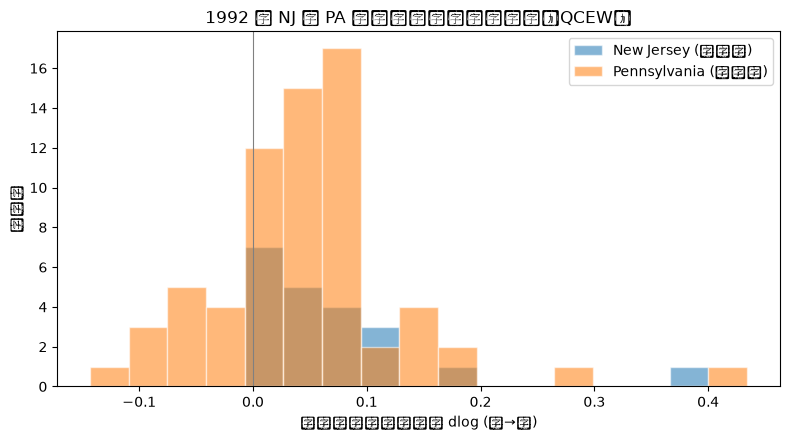

In [6]:
# ===== 7. 就业对数变化的分布对比 =====
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(d["dlog"].min() - 0.02, d["dlog"].max() + 0.02, 18)
ax.hist(d.loc[d.nj == 1, "dlog"], bins=bins, alpha=0.55, color="tab:blue",
        label="New Jersey (处理组)", edgecolor="white")
ax.hist(d.loc[d.nj == 0, "dlog"], bins=bins, alpha=0.55, color="tab:orange",
        label="Pennsylvania (对照组)", edgecolor="white")
ax.axvline(0, color="gray", linewidth=0.8)
ax.set(xlabel="餐饮业就业对数变化 dlog (前→后)",
       ylabel="县数量",
       title="1992 年 NJ 与 PA 县餐饮业就业变化分布（QCEW）")
ax.legend()
fig.tight_layout()
plt.show()


## 8. 结果解读与和原文的对比

**本扩展的结果**（用公开 QCEW 行政数据、县层面、SIC 58 餐饮业）：

- NJ 县餐饮业就业对数变化 ≈ **+0.073**（+7.3%），PA 县 ≈ **+0.046**（+4.6%）。
- **DiD ≈ +0.026**（即 NJ 相对 PA 多增长约 2.6 个百分点），标准误 0.020，t≈1.30，**p≈0.20，统计上不显著**。

**含义**：从行政工资记录的加总层面看，1992 年 4 月 NJ 最低工资上调**没有**导致 NJ 餐饮业就业相对 PA 下降；点估计甚至是正的（NJ 相对 PA 略有更快增长），只是不显著。这与 Card & Krueger (1994) 的结论方向一致（"无就业损失"）。

### 与原文/后续文献的关系（务必在报告里写清楚）

1. **方向一致、量级不同**：原文门店级 DiD ≈ +2.76 FTE（约 +13%），本扩展县层面 ≈ +2.6%。两者都为正，但口径不同（门店 vs 县；快餐连锁 vs 全部餐饮场所），不可直接比大小。
2. **一个重要发现**：CK 电话调查里 **PA 就业是下降的**（−2.16 FTE），而 QCEW 行政数据里 **PA 是上升的**（+4.6%）。这正是 Card & Krueger (1998 NBER) 用保密 ES-202 数据指出的：原调查中 PA 的下降是异常的（可能来自样本/测量问题）。我们的公开 QCEW 复现同样支持"PA 并未下降"这一点。
3. **局限性（诚实声明）**：
   - SIC 58 是"所有餐饮场所"（含正餐、酒吧），**不是**只挑快餐连锁，因此这是"加总餐饮业"的检验，不是逐店复现。
   - 县层面丢失了门店间的异质性；且只有 2 个"处理簇"（州），经典标准误可能偏乐观（这也是为什么 p≈0.20 不能过度解读）。
   - 1992 年 QCEW 用的是 SIC 分类，历史数据可能存在口径调整。

**结论一句话**：换用官方行政数据、在县级加总层面重新做 DiD，仍然找不到最低工资上调导致 NJ 餐饮业就业相对下降的证据，方向与原文一致。

### 可以继续做的稳健性（供你扩展报告使用）
- 把 `after` 换成 **Q4 全季度**（10+11+12 月）或 **Q1 全季度**（1+2+3 月）。
- 只用 **东部 PA 县**（与 NJ 相邻的 Bucks/Chester/Delaware/Montgomery/Northampton/Lehigh 等）作对照组，样本更可比。
- 把结果变量换成 **机构数** `qtrly_estabs_count` 或 **平均周薪** `avg_wkly_wage`。
- 加入县人口/面积等控制（需另找数据）。
